In [14]:

import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [15]:

!pip install -q "diffusers==0.35.2" "transformers==4.57.1" accelerate safetensors pillow matplotlib

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Sketch1


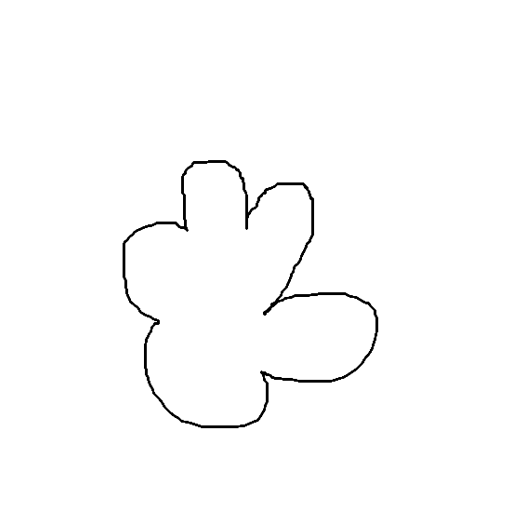

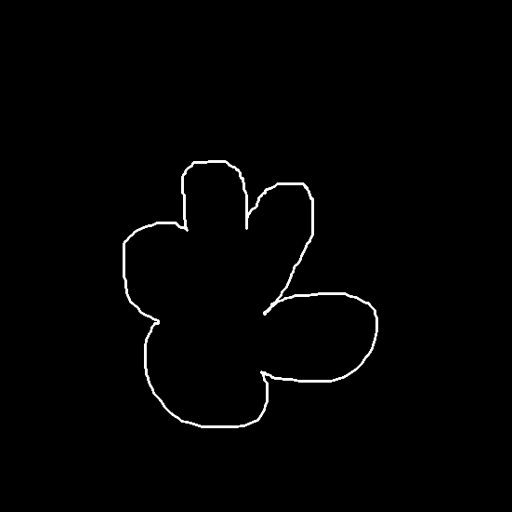

Sketch2


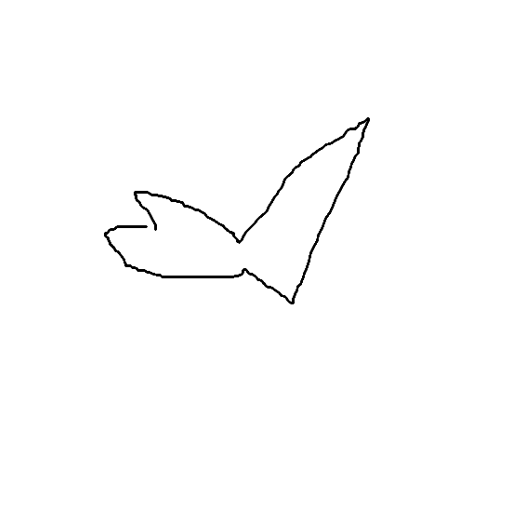

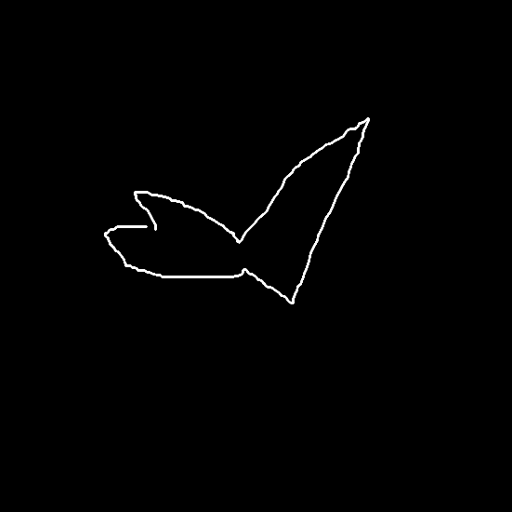

Sketch3


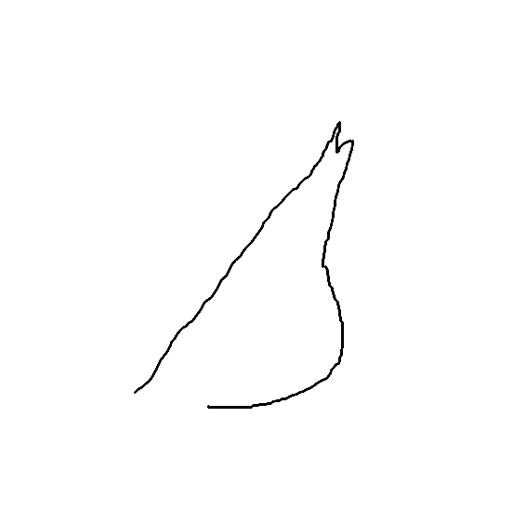

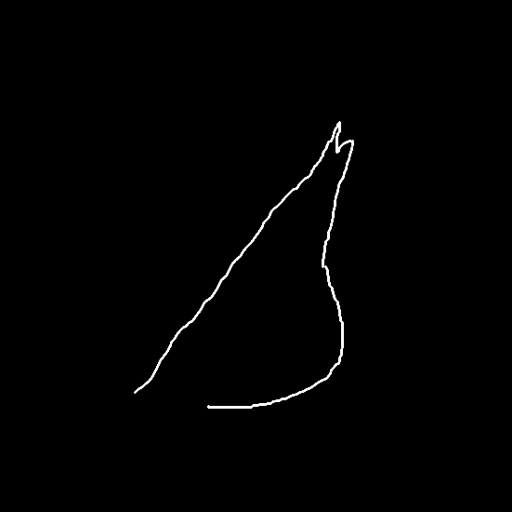

In [16]:

from pathlib import Path
from PIL import Image, ImageOps

root = Path("/content/drive/MyDrive")
names = ["Sketch1", "Sketch2", "Sketch3"]

# Find the original sketches
sketch_files = {}

for name in names:
    matches = list(root.glob(
        f"Machine learning project_Sketch*/**/{name}.png"
    ))
    if not matches:
        raise FileNotFoundError(f"Missing: {name}.png")
    sketch_files[name] = matches[0]

# Prepare ControlNet input images
controls = {}

for name in names:
    image = Image.open(sketch_files[name]).convert("RGB")
    image = ImageOps.pad(image, (512, 512), color="white")
    controls[name] = ImageOps.invert(image)

    print(name)
    display(image, controls[name])

In [17]:

import torch
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline,
    UniPCMultistepScheduler
)

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_scribble",
    torch_dtype=torch.float16
)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16
)

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.enable_model_cpu_offload()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/999 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

... (11 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/20 [00:00<?, ?it/s]

Sketch1 Generated:


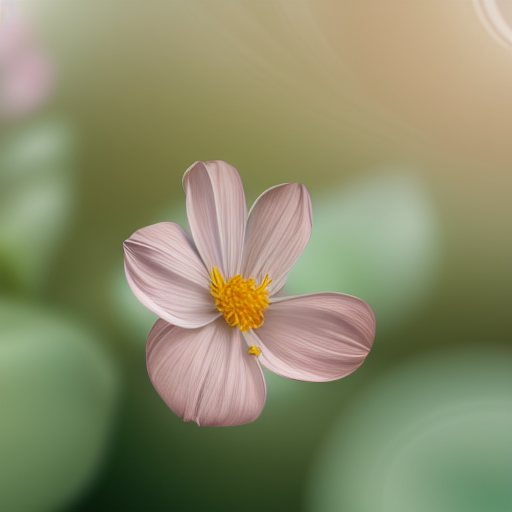

  0%|          | 0/20 [00:00<?, ?it/s]

Sketch2 Generated:


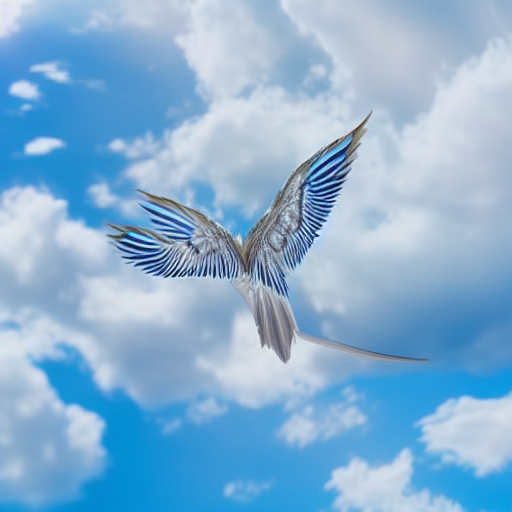

  0%|          | 0/20 [00:00<?, ?it/s]

Sketch3 Generated:


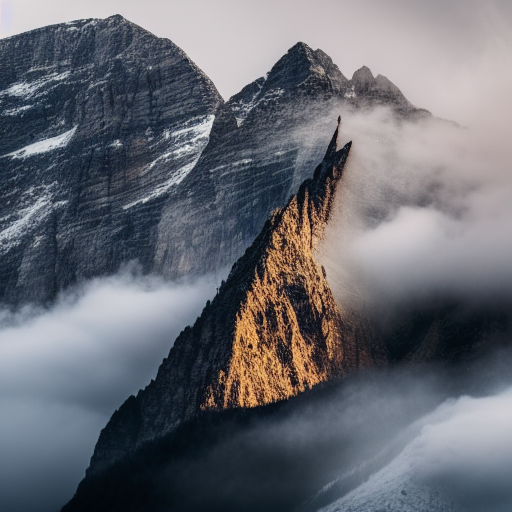

In [18]:

prompts = [
    "A beautiful realistic flower with five rounded petals, "
    "natural colors, detailed petals, soft sunlight, garden background",

    "A realistic bird flying in the sky with wings spread wide, "
    "detailed feathers, natural lighting, blue sky background",

    "A majestic mountain peak with a sharp summit, "
    "rocky textures, realistic landscape photography, natural lighting"
]

output_dir = root / "Machine learning project_Sketch" / "Results"
output_dir.mkdir(parents=True, exist_ok=True)

for name, prompt in zip(names, prompts):
    image = pipe(
        prompt=prompt,
        image=controls[name],
        num_inference_steps=20,
        guidance_scale=7.5,
        controlnet_conditioning_scale=1.0,
        generator=torch.Generator("cpu").manual_seed(42)
    ).images[0]

    image.save(output_dir / f"{name}_generated.png")
    print(name, "Generated:")
    display(image)


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

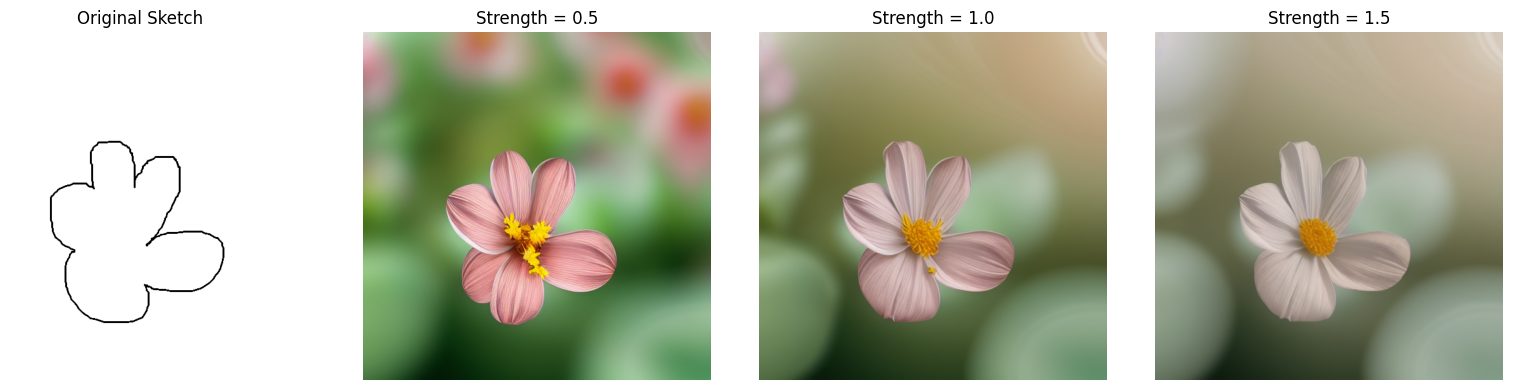

In [19]:

import matplotlib.pyplot as plt

strengths = [0.5, 1.0, 1.5]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(Image.open(sketch_files["Sketch1"]))
axes[0].set_title("Original Sketch")

for i, strength in enumerate(strengths, 1):
    image = pipe(
        prompt=prompts[0],
        image=controls["Sketch1"],
        num_inference_steps=20,
        guidance_scale=7.5,
        controlnet_conditioning_scale=strength,
        generator=torch.Generator("cpu").manual_seed(42)
    ).images[0]

    axes[i].imshow(image)
    axes[i].set_title(f"Strength = {strength}")
    image.save(output_dir / f"strength_{strength}.png")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(output_dir / "comparison.png", dpi=150)
plt.show()
